In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("titanic_cleaned.csv")

# Display first five rows
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Check missing values
print("\nTotal missing values:", df.isnull().sum().sum())


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


Dataset shape: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        891 non-null    object 
 11  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Total missing values: 0


In [2]:

# 1. Summary of numerical columns
print("Numerical Statistical Summary:")
display(df.describe().T.round(2))

# 2. Count of passengers by survival status
print("\nSurvival Count:")
print(df["Survived"].value_counts())

# 3. Survival percentage
print("\nSurvival Percentage:")
print((df["Survived"].value_counts(normalize=True) * 100).round(2))

# 4. Passenger count by gender
print("\nPassengers by Gender:")
print(df["Sex"].value_counts())

# 5. Passenger count by passenger class
print("\nPassengers by Class:")
print(df["Pclass"].value_counts().sort_index())

# 6. Average age and fare
print("\nAverage Age:", round(df["Age"].mean(), 2))
print("Median Age:", round(df["Age"].median(), 2))
print("Average Fare:", round(df["Fare"].mean(), 2))


Numerical Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.00,257.35,1.00,223.50,446.00,668.5,891.00
Survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Age,891.0,29.36,13.02,0.42,22.00,28.00,35.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33



Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64

Passengers by Gender:
Sex
male      577
female    314
Name: count, dtype: int64

Passengers by Class:
Pclass
1    216
2    184
3    491
Name: count, dtype: int64

Average Age: 29.36
Median Age: 28.0
Average Fare: 32.2


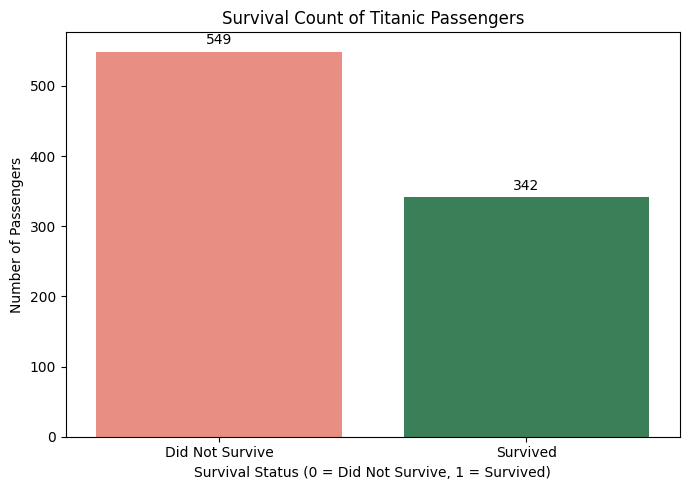

In [3]:

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Survived",
    hue="Survived",
    palette={0: "salmon", 1: "seagreen"},
    legend=False
)

plt.title("Survival Count of Titanic Passengers")
plt.xlabel("Survival Status (0 = Did Not Survive, 1 = Survived)")
plt.ylabel("Number of Passengers")
plt.xticks([0, 1], ["Did Not Survive", "Survived"])

# Add count labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()


Survival Rate by Gender (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


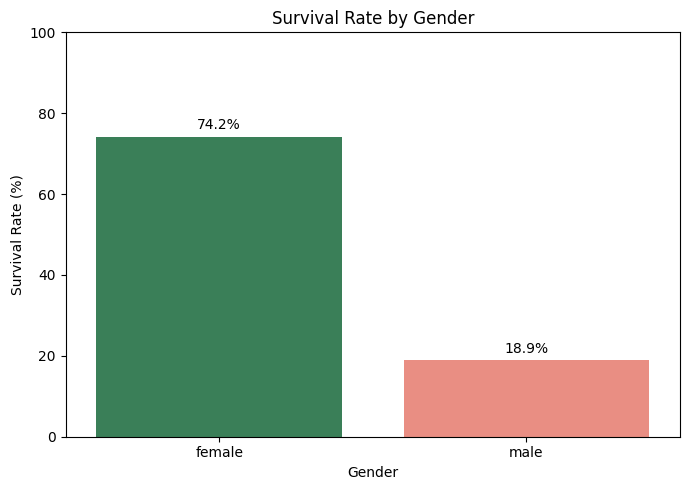

In [4]:

# Calculate survival rate for each gender
gender_survival = df.groupby("Sex")["Survived"].mean() * 100

print("Survival Rate by Gender (%):")
print(gender_survival.round(2))

# Create the visualization
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=gender_survival.index,
    y=gender_survival.values,
    hue=gender_survival.index,
    palette={"female": "seagreen", "male": "salmon"},
    legend=False
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


Survival Rate by Passenger Class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


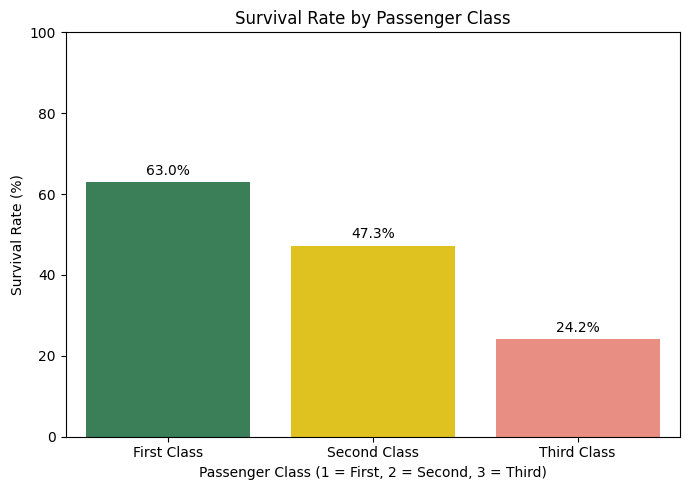

In [5]:

# Calculate survival rate by passenger class
class_survival = df.groupby("Pclass")["Survived"].mean() * 100

print("Survival Rate by Passenger Class (%):")
print(class_survival.round(2))

# Create the visualization
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=class_survival.index,
    y=class_survival.values,
    hue=class_survival.index,
    palette={1: "seagreen", 2: "gold", 3: "salmon"},
    legend=False
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate (%)")
plt.xticks([0, 1, 2], ["First Class", "Second Class", "Third Class"])
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


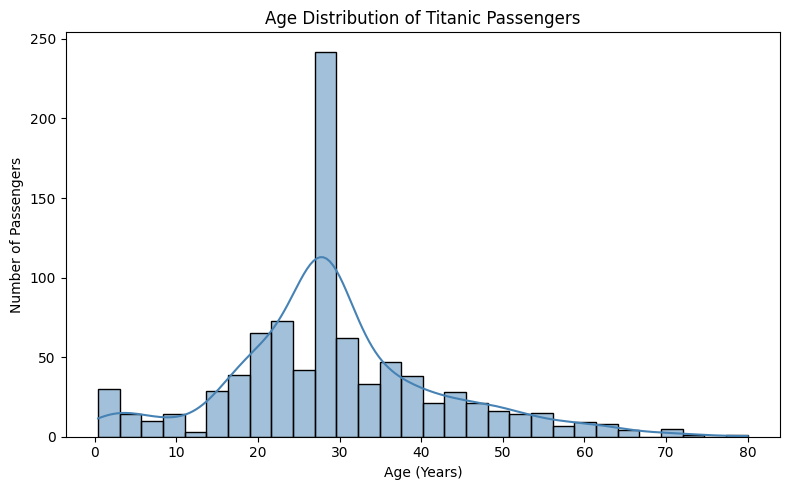

In [6]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


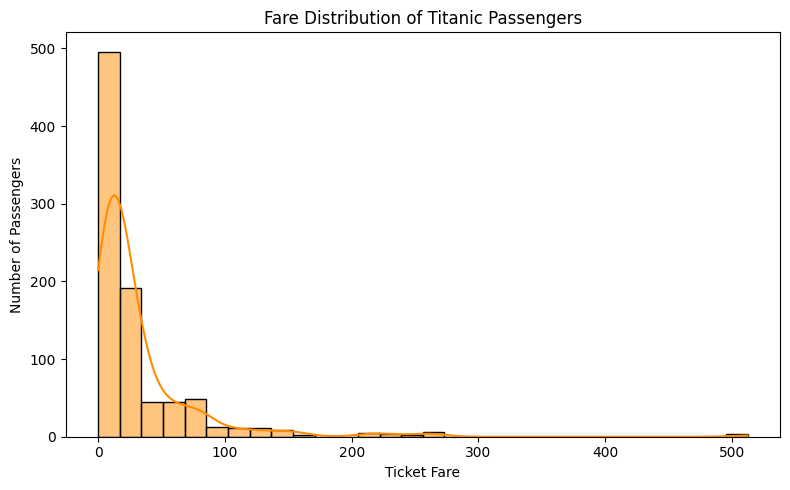

In [7]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Fare",
    bins=30,
    kde=True,
    color="darkorange"
)

plt.title("Fare Distribution of Titanic Passengers")
plt.xlabel("Ticket Fare")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


   Pclass     Sex  Survived  Survival Rate (%)
0       1  female      0.97              96.81
1       1    male      0.37              36.89
2       2  female      0.92              92.11
3       2    male      0.16              15.74
4       3  female      0.50              50.00
5       3    male      0.14              13.54


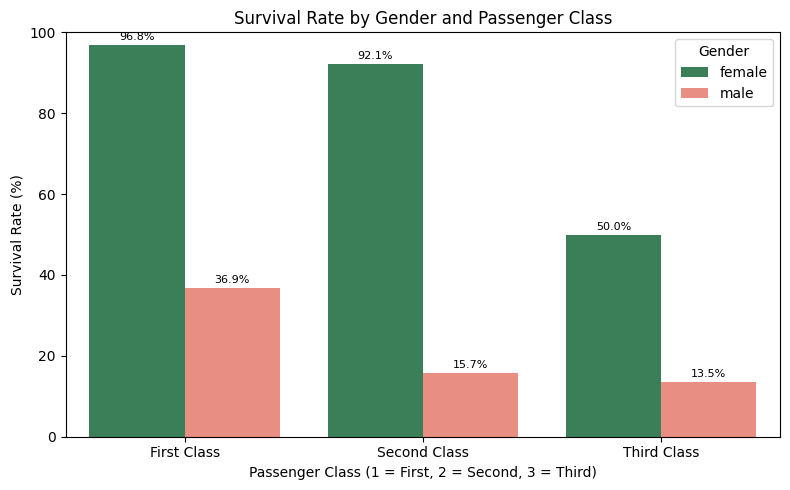

In [8]:

# Calculate survival rate by gender and passenger class
survival_gender_class = (
    df.groupby(["Pclass", "Sex"])["Survived"]
    .mean()
    .reset_index()
)

survival_gender_class["Survival Rate (%)"] = (
    survival_gender_class["Survived"] * 100
)

print(survival_gender_class.round(2))

# Create grouped bar chart
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=survival_gender_class,
    x="Pclass",
    y="Survival Rate (%)",
    hue="Sex",
    palette={"female": "seagreen", "male": "salmon"}
)

plt.title("Survival Rate by Gender and Passenger Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate (%)")
plt.xticks([0, 1, 2], ["First Class", "Second Class", "Third Class"])
plt.ylim(0, 100)
plt.legend(title="Gender")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=8)

plt.tight_layout()
plt.show()


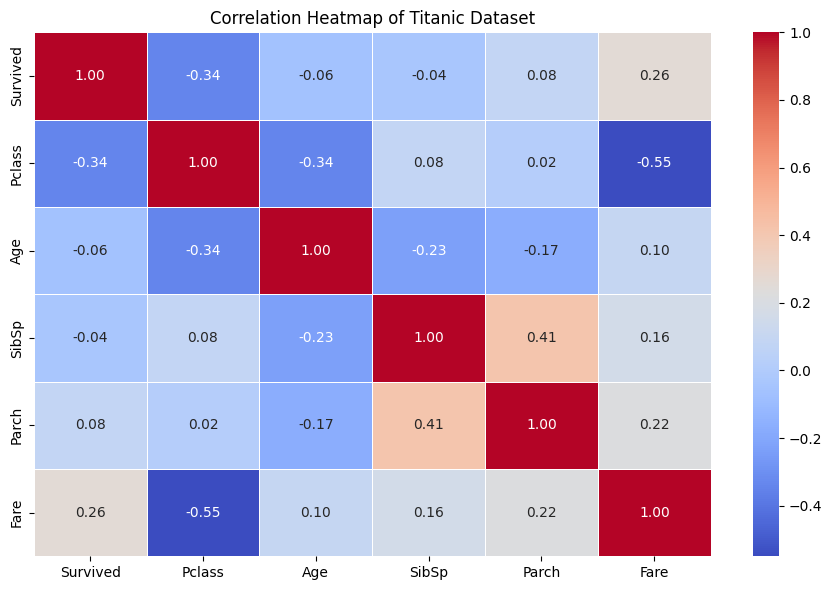

In [9]:

# Select numerical columns for correlation analysis
numeric_df = df[
    ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
]

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Titanic Dataset")
plt.tight_layout()
plt.show()
